# MNIST Classification with MLP (1)

In [1]:
import torch
import torch.nn as nn
from torchvision import datasets
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


## 1. Load MNIST

In [2]:
dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True
)

# Use 30,000 images for faster training
X_train = dataset.data[:20000].float() / 255.0
y_train = dataset.targets[:20000]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

X_train: torch.Size([20000, 28, 28])
y_train: torch.Size([20000])


## 2. Define MLP

In [3]:
class MyMlp(nn.Module):
    def __init__(self):
        super().__init__()

        # Fully-connected (fc) layers
        self.W1 = nn.Linear(784, 128)
        self.W2 = nn.Linear(128, 64)
        self.W3 = nn.Linear(64, 10)

        # ReLU activation function
        self.relu = nn.ReLU()

    def forward(self, x):
        z1 = self.W1(x)
        h1 = self.relu(z1)

        z2 = self.W2(h1)
        h2 = self.relu(z2)

        y = self.W3(h2)

        return y

model = MyMlp().to(device)
print(model)

MyMlp(
  (W1): Linear(in_features=784, out_features=128, bias=True)
  (W2): Linear(in_features=128, out_features=64, bias=True)
  (W3): Linear(in_features=64, out_features=10, bias=True)
  (relu): ReLU()
)


## 3. Train

In [4]:
# CrossEntropyLoss internally applies Softmax
loss_function = nn.CrossEntropyLoss()

# Optimizer
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

# Training settings
num_epochs = 30
batch_size = 64

# Move data to selected device (CPU or GPU)
X_train = X_train.to(device)
y_train = y_train.to(device)

for epoch in range(num_epochs):

    # Set the model to training mode
    model.train()

    total_loss = 0

    # Divide the data into mini-batches
    for start in range(0, len(X_train), batch_size):

        end = start + batch_size

        # Get one mini-batch
        images = X_train[start:end]
        labels = y_train[start:end]

        # Flatten: [batch, 28, 28] -> [batch, 784]
        images = images.reshape(images.size(0), 28 * 28)

        # Forwarding
        outputs = model(images)

        # Compute loss
        loss = loss_function(outputs, labels)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()

        # Update weights
        optimizer.step()

        total_loss += loss.item()

    # Average loss
    avg_loss = total_loss / ((len(X_train) + batch_size - 1) // batch_size)

    print( f"Epoch [{epoch+1}/{num_epochs}] Loss: {avg_loss:.4f}")

Epoch [1/30] Loss: 2.2493
Epoch [2/30] Loss: 1.8946
Epoch [3/30] Loss: 1.1180
Epoch [4/30] Loss: 0.6936
Epoch [5/30] Loss: 0.5339
Epoch [6/30] Loss: 0.4579
Epoch [7/30] Loss: 0.4146
Epoch [8/30] Loss: 0.3863
Epoch [9/30] Loss: 0.3658
Epoch [10/30] Loss: 0.3497
Epoch [11/30] Loss: 0.3363
Epoch [12/30] Loss: 0.3248
Epoch [13/30] Loss: 0.3146
Epoch [14/30] Loss: 0.3054
Epoch [15/30] Loss: 0.2969
Epoch [16/30] Loss: 0.2890
Epoch [17/30] Loss: 0.2817
Epoch [18/30] Loss: 0.2747
Epoch [19/30] Loss: 0.2681
Epoch [20/30] Loss: 0.2618
Epoch [21/30] Loss: 0.2558
Epoch [22/30] Loss: 0.2500
Epoch [23/30] Loss: 0.2445
Epoch [24/30] Loss: 0.2391
Epoch [25/30] Loss: 0.2339
Epoch [26/30] Loss: 0.2289
Epoch [27/30] Loss: 0.2239
Epoch [28/30] Loss: 0.2191
Epoch [29/30] Loss: 0.2145
Epoch [30/30] Loss: 0.2099


## 4. Check Learned Model

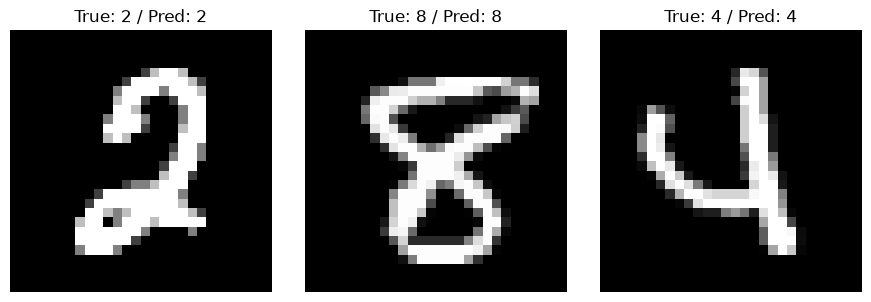

In [5]:
# Randomly select 3 images
indices = torch.randperm(len(X_train), device=device)[:3]

X_check = X_train[indices]
y_check = y_train[indices]

# Set the model to evaluation mode
model.eval()

# Disable gradient calculation
with torch.no_grad():
    X_check_flat = X_check.reshape(3, 28 * 28)
    outputs = model(X_check_flat)
    predictions = outputs.argmax(dim=1)

# Show 3 images
fig, axes = plt.subplots(1, 3, figsize=(9, 3))

for i in range(3):
    axes[i].imshow(X_check[i].cpu(), cmap="gray")
    axes[i].set_title(f"True: {y_check[i].item()} / Pred: {predictions[i].item()}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()
